testing the new adcCtrl algorithm in a notebook before I distill it into a .py file. this is just the work in progress.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from hcipy import *
from scipy.optimize import minimize
from scipy.optimize import curve_fit
from scipy import ndimage
from psfGenerator_26B import psf

first, we need an image to play with. let's start with a simulated image, then we'll move on to a real one once we get the ball rolling.

### Broadband dispersed PSF generator

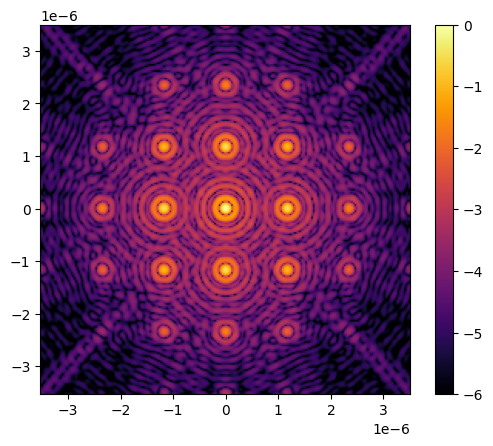

In [3]:
#overall parameters
telescope_diameter = 6.5 # meter
oversizing_factor = 1 #how much extra space next to the pupil (1 = no padding)
wavelength = 762E-9 #m, center wavelength
bandwidth = 120E-9 #m

grating_angle = 0
grating_fx = 10
grating_fy = 10

#define pupil grid
num_pupil_pixels = 128
pupil_grid_diameter = telescope_diameter * oversizing_factor
pupil_grid = make_pupil_grid(num_pupil_pixels, pupil_grid_diameter)

#create pupil
magellan_aperture_generator = make_magellan_aperture(False) #diameter is automatically 6.5
magellan_aperture = evaluate_supersampled(magellan_aperture_generator, pupil_grid, 4)
imshow_field(magellan_aperture)

#set up wavefront for propagation
wf = Wavefront(magellan_aperture, wavelength)
wf.total_power = 1

#propagator
spatial_resolution = wavelength / telescope_diameter
focal_grid = make_focal_grid(q=4, num_airy=30, spatial_resolution=spatial_resolution)

propagator = FraunhoferPropagator(pupil_grid, focal_grid)

###diffraction grating
#creating the cosine pattern
grating_grid = magellan_aperture.grid
rotated_grid = grating_grid.rotated(grating_angle)
cos_pattern_x = Field(np.cos(2*np.pi*(grating_fx/telescope_diameter) * rotated_grid.x),grating_grid)
cos_pattern_y = Field(np.cos(2*np.pi*(grating_fy/telescope_diameter) * rotated_grid.y),grating_grid)

#applying the cosine pattern to the phase apodizer
grating = PhaseApodizer(cos_pattern_x+cos_pattern_y)

#propagation
wf1 = grating.forward(wf)
wf2 = propagator.forward(wf1).power

imshow_field(np.log10(wf2 / wf2.max()), cmap='inferno', vmin=-6)
plt.colorbar()
plt.show()


In [4]:
magnitude_x = 0
magnitude_y = 0
mask = False

def disp(lam,lam0): #linear function of wavelength and the center wavelength
    dist = (lam - lam0) #distance from center wavelength
    return -dist

bb_psf = 0
                
for wlen in np.linspace(wavelength - bandwidth / 2., wavelength + bandwidth / 2., 15):
    k = 2 * np.pi / wlen #wavemumber
    opd_y = magnitude_y * disp(wlen,wavelength) * pupil_grid.y
    opd_x = magnitude_x * disp(wlen,wavelength) * pupil_grid.x
    opd = opd_y + opd_x 
    phase = opd * k #optical path difference between dispersed & not dispersed
    
    wf1 = Wavefront(magellan_aperture * np.exp(1j*phase),wavelength=wlen)
    wf1.total_power = 1/13 #normalizing each wavefront so that the total number of photons is 1 in the BB PSF
    wf2 = grating.forward(wf1)
    wf3 = propagator.forward(wf2)
    power = wf3.power
    
    if mask == True:
        mask_ap = make_circular_aperture(wavelength*10,[center_x * wavelength,center_y * wavelength])
        masking = mask_ap(power.grid)
        masking = np.abs(masking - 1)
        power *= masking
    
    bb_psf += power

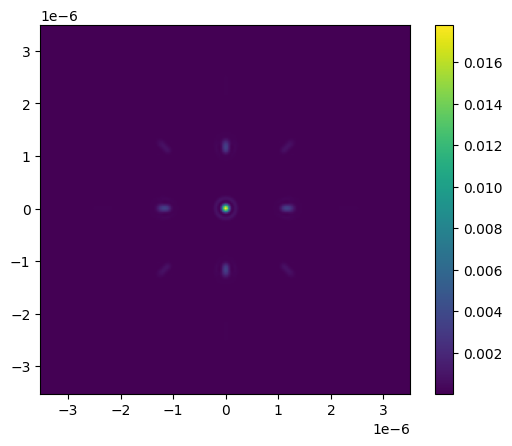

In [5]:
imshow_field(bb_psf)
plt.colorbar()

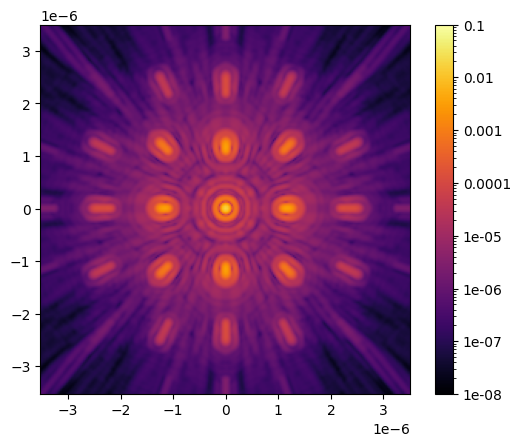

In [14]:
#testing the function written in the psfGenerator_26.py file
disp_y = 0

test = psf(wavelength,bandwidth,dispersion_y =disp_y)
imshow_psf(test)

### making sure the psf generator is in real units

In [18]:
#now calculate the size of the central PSF in mas
def gauss(x,mu,sigma2):
    return np.exp(-(x-mu)**2 / (2 * sigma2) )

def isolate_gaussian(data):
    mid = np.argmax(data)
    first_derivative = np.gradient(data) 

    valley_indices = np.where((first_derivative[:-1] < 0) & (first_derivative[1:] > 0))[0] + 1

    left_valley = valley_indices[valley_indices < mid][-1] if any(valley_indices < mid) else None
    right_valley = valley_indices[valley_indices > mid][0] if any(valley_indices > mid) else None

    if left_valley is not None:
        data[0:left_valley] = 0
        #right_valley -= left_valley

    if right_valley is not None:
        data[right_valley:len(data)-1] = 0
        #print(right_valley)

    return data

def fwhm(data,mean_est=0):
    isolated = isolate_gaussian(data)
    x = np.arange(len(isolated))
    popt = curve_fit(gauss,x,isolated,p0=np.array([120,10]))

    mu = popt[0][0]
    sigma = popt[0][1]
    fwhm = 2 * np.sqrt(2 * np.log(2)) * np.sqrt(sigma)
    return fwhm, mu, sigma

#define a function that takes in the psf and spits out the vertical FWHM, with the option to provide the plot for diagnostic purposes
def psf_vertical_fwhm(data,plotted=False):
    sliced = data.shaped[:,int(np.sqrt(data.size)/2)]
    sliced /= sliced.max()
    s = isolate_gaussian(sliced)
    width, mean, sd = fwhm(s,mean_est = len(sliced)/2 )

    if plotted:
        x = np.arange(len(s))
        #print(f'FWHM: {width}')

        plt.figure()
        plt.plot(x,s,'-o',label='Data')
        plt.plot(x,gauss(x,mean,sd),'r-',label='Fitted Gaussian')
        plt.vlines(mean - width/2,0,1,'gray',label=f'FWHM: {width:.3f}')
        plt.vlines(mean + width/2,0,1,'gray')
        plt.legend()
        plt.show()

    return width

/var/folders/lz/tstdmcf92cv45_pgvnk0mkgr0000gn/T/ipykernel_27347/3223895478.py:3: RuntimeWarning: overflow encountered in exp
  return np.exp(-(x-mu)**2 / (2 * sigma2) )


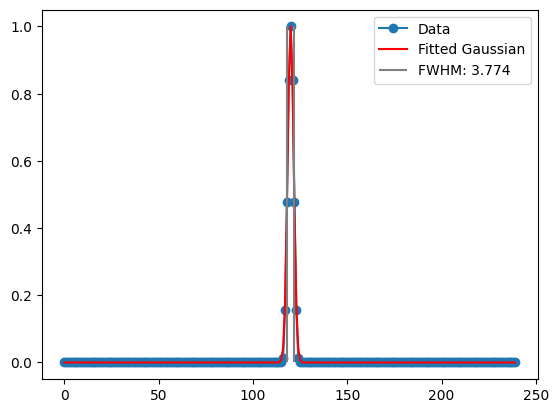

In [20]:
fwhm_test = psf_vertical_fwhm(test,plotted=True)

In [24]:
(wavelength / telescope_diameter) / 4

2.9307692307692306e-08

there are four pixels per resolution element, per the line that creates the focal grid (q=4). lam / D = 1.1723076923076922e-07, lam/D /4 = 2.93E-8, which means each pixel's angular size (in radians) is that ^^. this is also the grid.delta value. so we just need to convert that number into mas, and then we multiply the gaussian FWHM in pixels by that conversion factor to get PSF size in mas.

In [25]:
pix_size_mas = bb_psf.grid.delta * 206265 * 1000
print(pix_size_mas)

[6.04515115 6.04515115]


so we have about 6 mas/pixel. coincidentally this is almost the exact platescale of magao-x, except magao-x has a lot more pixels in the focal plane. so i suppose if i just changed the extent parameter in the focal grid generator, i would have a pretty decent analog of what's going on on the magao-x science cameras.